# SkillPulse: Exploratory Data Analysis (EDA)

**Goal:** understand the job-postings data *before* building features on it: what we have,
how good it is, what it can and can't tell us.

**Data:** job postings collected nightly from the Adzuna API (India), cleaned and stored in
PostgreSQL by the SkillPulse pipeline, with skills extracted by our dictionary extractor.

**How to read this notebook:** every section has a short *"What this shows"* note in plain
language. Figures are also saved to `reports/figures/` for the project report.

> Re-running this notebook gives updated numbers, because new jobs arrive every night.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from skillpulse.db.connection import get_connection  # noqa: E402

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# SkillPulse chart style (same colours as the app; checked for colour-blind safety)
INK, INK3, GRID, C1 = "#1C1C1C", "#6A7272", "#E4EBEB", "#4A4FD6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK3, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
})
pd.set_option("display.max_rows", 40)


def q(sql, params=None):
    with get_connection() as c:
        cur = c.execute(sql, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])


def hbar(series, title, xlabel, fname, pct=False, color=C1):
    """Ranked horizontal bar chart, one colour, value labels at the bar end."""
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(s) + 0.9))
    ax.barh(s.index, s.values, color=color, height=0.62)
    for y, v in enumerate(s.values):
        ax.text(v, y, f" {v:.0f}%" if pct else f" {v:,.0f}", va="center", color=INK3, fontsize=9)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.savefig(FIG / fname); plt.show()

## 1. What data do we have?

**What this shows:** the size of the dataset, the dates it covers, and how much of it is
usable for skill analysis.

In [2]:
jobs = q('''
    SELECT j.id, j.title, r.name AS role, j.company, j.city, j.state,
           j.salary_min::float AS salary_min, j.salary_max::float AS salary_max,
           (coalesce(j.posted_at, j.fetched_at) AT TIME ZONE 'Asia/Kolkata')::date AS day,
           length(j.description) AS desc_len,
           (SELECT count(*) FROM job_skills s WHERE s.job_id = j.id) AS n_skills
    FROM jobs j LEFT JOIN roles r ON r.id = j.role_id''')
runs = q("SELECT count(*) AS runs, sum(api_calls) AS api_calls FROM pipeline_runs WHERE status <> 'failed'")

overview = pd.Series({
    "Job postings stored": len(jobs),
    "Date range (posted)": f"{jobs.day.min()} to {jobs.day.max()}",
    "Days covered": jobs.day.nunique(),
    "Distinct companies": jobs.company.nunique(),
    "Mapped to one of our 10 roles": f"{jobs.role.notna().mean():.0%}",
    "With at least one skill found": f"{(jobs.n_skills > 0).mean():.0%}",
    "With an advertised salary": f"{jobs.salary_min.notna().mean():.1%}",
    "Pipeline runs / API calls used": f"{runs.runs[0]} / {runs.api_calls[0]}",
})
overview.to_frame("value")

,value
Job postings stored,1463
Date range (posted),2026-11-20 to 2026-11-24
Days covered,5
Distinct companies,619
Mapped to one of our 10 roles,48%
With at least one skill found,65%
With an advertised salary,6.4%
Pipeline runs / API calls used,2 / 98


## 2. Which roles and cities?

**What this shows:** how many postings each role and city has. Small groups give
unreliable percentages, so the app warns when a sample is small.

Jobs that don't match any of our 10 roles (e.g. *"Scrum Master"* returned for a
*"data analyst"* search) are kept, but left out of role statistics.

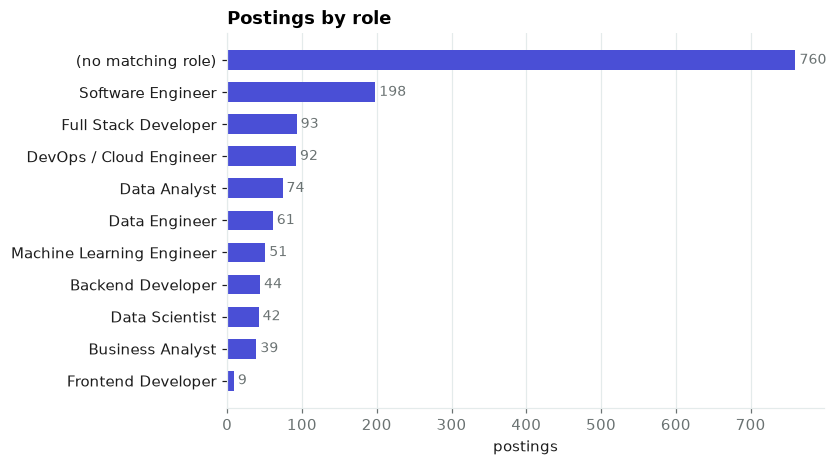

In [3]:
role_counts = jobs.role.fillna("(no matching role)").value_counts()
hbar(role_counts, "Postings by role", "postings", "01_roles.png")

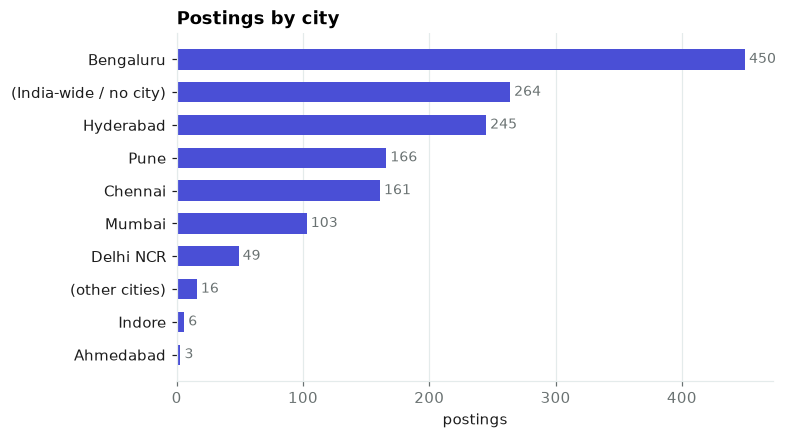

In [4]:
city_counts = jobs.city.fillna("(India-wide / no city)")
top = city_counts.value_counts()
other = top.iloc[9:].sum()
top = pd.concat([top.iloc[:9], pd.Series({"(other cities)": other})])
hbar(top, "Postings by city", "postings", "02_cities.png")

In [5]:
# Role x city table (mapped jobs, tracked cities) - shows how thin some groups are
tracked = ["Bengaluru", "Hyderabad", "Pune", "Chennai", "Mumbai", "Delhi NCR"]
pd.crosstab(jobs.role, jobs.city.where(jobs.city.isin(tracked), "Other/India-wide"), margins=True)

city,Bengaluru,Chennai,Delhi NCR,Hyderabad,Mumbai,Other/India-wide,Pune,All
role,,,,,,,,
Backend Developer,15,8,1,5,2,4,9,44
Business Analyst,16,6,1,5,5,2,4,39
Data Analyst,25,10,5,3,7,18,6,74
Data Engineer,18,8,4,14,2,9,6,61
Data Scientist,15,4,2,6,0,10,5,42
DevOps / Cloud Engineer,30,10,4,15,10,15,8,92
Frontend Developer,4,0,1,0,0,4,0,9
Full Stack Developer,22,9,1,19,4,26,12,93
Machine Learning Engineer,15,1,1,9,1,19,5,51


## 3. How much text do we get per job?

**What this shows:** Adzuna gives only a **preview** of each description, not the full job ad.
This is the single biggest limit on how many skills we can find.

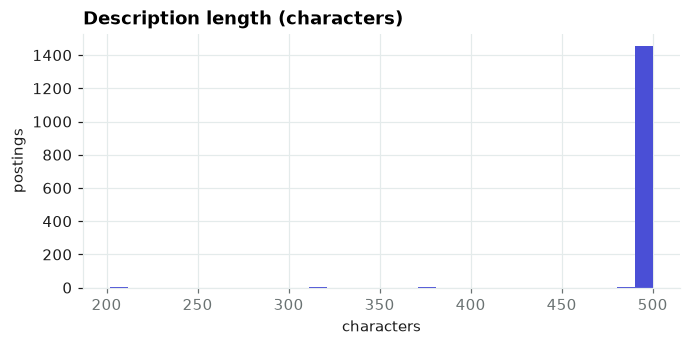

,count,mean,std,min,25%,50%,75%,max
characters,1463.0,499.0,10.0,202.0,500.0,500.0,500.0,500.0


In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(jobs.desc_len.dropna(), bins=30, color=C1)
ax.set_title("Description length (characters)"); ax.set_xlabel("characters"); ax.set_ylabel("postings")
fig.savefig(FIG / "03_desc_length.png"); plt.show()
jobs.desc_len.describe().round(0).to_frame("characters").T

## 4. How many skills per job?

**What this shows:** how many skills the extractor found per posting. Zero usually means
the preview contained only a company description.

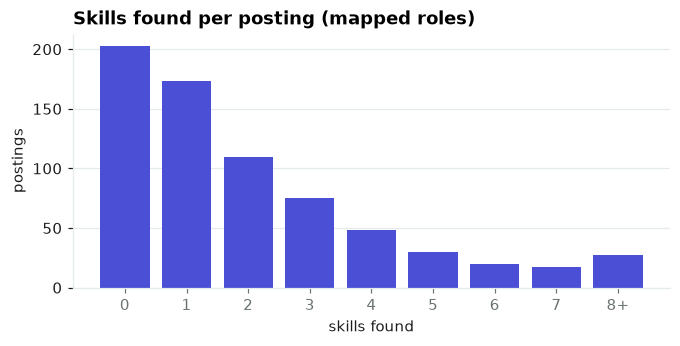

Postings with 0 skills: 29% · median among the rest: 2


In [7]:
mapped = jobs[jobs.role.notna()]
dist = mapped.n_skills.clip(upper=8).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar([str(i) if i < 8 else "8+" for i in dist.index], dist.values, color=C1)
ax.set_title("Skills found per posting (mapped roles)"); ax.set_xlabel("skills found")
ax.set_ylabel("postings"); ax.grid(axis="x", visible=False)
fig.savefig(FIG / "04_skills_per_job.png"); plt.show()
print(f"Postings with 0 skills: {(mapped.n_skills == 0).mean():.0%} · "
      f"median among the rest: {mapped.loc[mapped.n_skills > 0, 'n_skills'].median():.0f}")

## 5. Which skills are most in demand?

**What this shows:** the % of postings (that list at least one skill) mentioning each skill.
Same definition as the app.

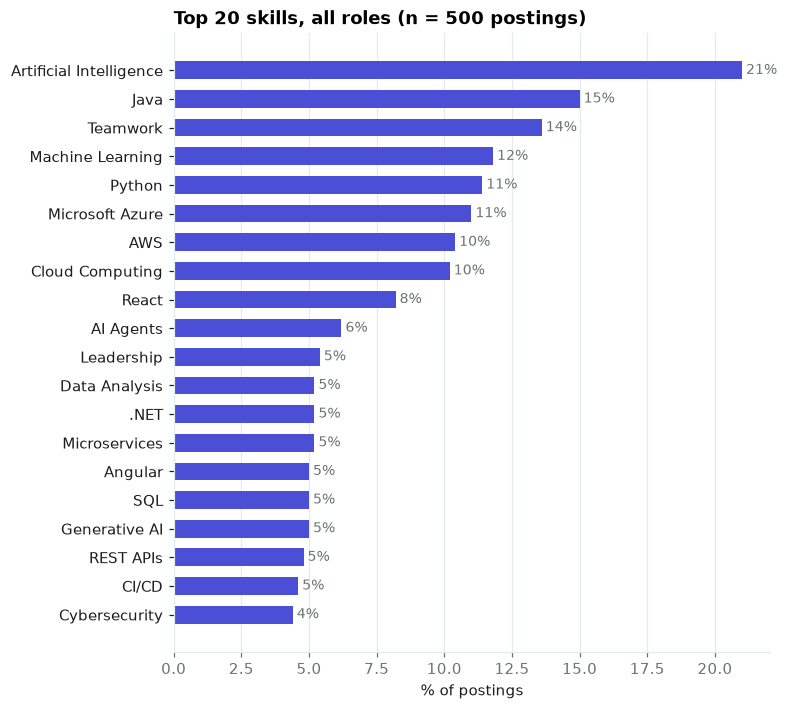

In [8]:
js = q('''
    SELECT s.job_id, k.name AS skill, k.category, r.name AS role
    FROM job_skills s JOIN skills k ON k.id = s.skill_id
    JOIN jobs j ON j.id = s.job_id JOIN roles r ON r.id = j.role_id''')
n_with_skills = js.job_id.nunique()
top_skills = js.groupby("skill").job_id.nunique().div(n_with_skills).mul(100).nlargest(20)
hbar(top_skills, f"Top 20 skills, all roles (n = {n_with_skills} postings)",
     "% of postings", "05_top_skills.png", pct=True)

In [9]:
# Top 5 skills for each role
per_role_total = js.groupby("role").job_id.nunique()
share = (js.groupby(["role", "skill"]).job_id.nunique()
           .div(per_role_total, level="role").mul(100).round(0))
top5 = (share.reset_index(name="pct").sort_values(["role", "pct"], ascending=[True, False])
            .groupby("role").head(5))
top5["skill (pct)"] = top5.skill + " (" + top5.pct.astype(int).astype(str) + "%)"
table = top5.groupby("role")["skill (pct)"].apply(list).apply(pd.Series)
table.columns = [f"#{i + 1}" for i in table.columns]
table.insert(0, "postings", per_role_total)
table

,postings,#1,#2,#3,#4,#5
role,,,,,,
Backend Developer,41,Java (56%),REST APIs (22%),Spring Boot (22%),Microservices (20%),Python (17%)
Business Analyst,17,Requirements Gathering (29%),User Stories (18%),Attention to Detail (12%),BRD/FRD (12%),Data Analysis (12%)
Data Analyst,47,Data Analysis (32%),Artificial Intelligence (15%),Power BI (15%),Teamwork (15%),Dashboarding (11%)
Data Engineer,43,Data Pipelines (26%),Microsoft Azure (26%),ETL (21%),Databricks (19%),Apache Spark (16%)
Data Scientist,26,Machine Learning (42%),Artificial Intelligence (38%),Python (15%),Teamwork (15%),AI Agents (12%)
DevOps / Cloud Engineer,64,Cloud Computing (36%),CI/CD (23%),Microsoft Azure (23%),Cybersecurity (20%),AWS (19%)
Frontend Developer,8,Artificial Intelligence (25%),Next.js (25%),REST APIs (25%),React (25%),Teamwork (25%)
Full Stack Developer,78,React (35%),Java (32%),Angular (24%),.NET (22%),Artificial Intelligence (19%)
Machine Learning Engineer,51,Artificial Intelligence (67%),Machine Learning (61%),Generative AI (22%),AI Agents (20%),Large Language Models (12%)


## 6. What *kind* of skills does each role need?

**What this shows:** for each role, the share of skill mentions by category (languages,
cloud, BI tools, soft skills, ...). Darker = bigger share. This shows how different the
roles really are.

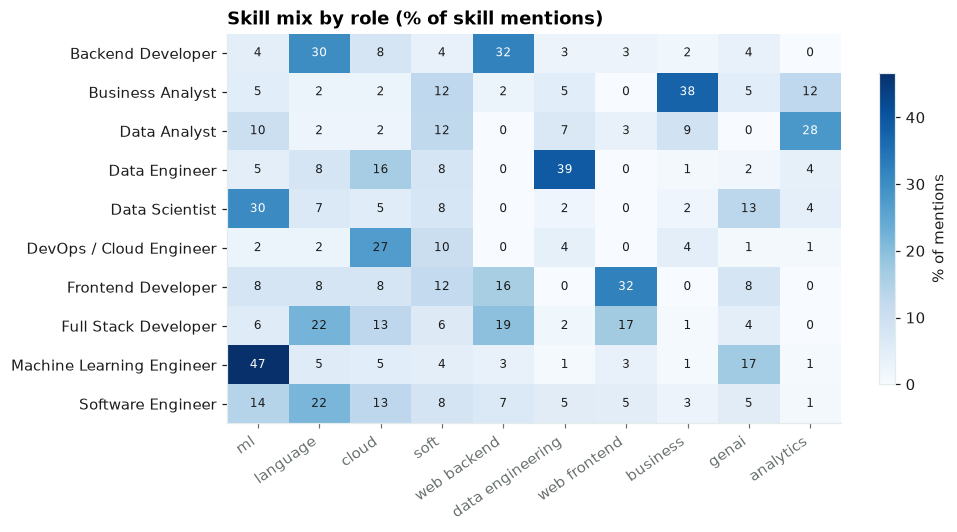

In [10]:
cat = (js.groupby(["role", "category"]).size().unstack(fill_value=0))
cat = cat.div(cat.sum(axis=1), axis=0).mul(100)
keep = cat.mean().nlargest(10).index
cat = cat[keep]
fig, ax = plt.subplots(figsize=(9, 4.6))
im = ax.imshow(cat.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(len(keep)), [k.replace("_", " ") for k in keep], rotation=35, ha="right")
ax.set_yticks(range(len(cat)), cat.index); ax.grid(False)
for (i, j), v in np.ndenumerate(cat.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
            color="white" if v > cat.values.max() * 0.6 else INK)
ax.set_title("Skill mix by role (% of skill mentions)")
fig.colorbar(im, ax=ax, shrink=0.8, label="% of mentions")
fig.savefig(FIG / "06_category_mix.png"); plt.show()

## 7. Which skills appear together?

**What this shows:** pairs of skills often asked for in the same posting.
**Lift** = how much more often they appear together than if they were unrelated
(lift 1 = no relation; lift 5 = five times more often than chance). Only pairs seen in
at least 8 postings are shown, so the lift isn't based on one or two jobs.

In [11]:
from itertools import combinations

baskets = js.groupby("job_id").skill.apply(lambda s: sorted(set(s)))
N = len(baskets)
single = js.groupby("skill").job_id.nunique()
pairs = pd.Series([p for b in baskets for p in combinations(b, 2)]).value_counts()
pairs = pairs[pairs >= 8]
co = pd.DataFrame({"postings": pairs})
co["lift"] = [(n / N) / ((single[a] / N) * (single[b] / N)) for (a, b), n in pairs.items()]
co.index = [f"{a} + {b}" for a, b in co.index]
co.sort_values("lift", ascending=False).round(1).head(15)

,postings,lift
Infrastructure as Code + Kubernetes,8,20.2
.NET + C#,14,19.2
Microservices + Spring Boot,17,14.9
REST APIs + Spring Boot,12,11.4
Microservices + REST APIs,12,9.6
Cloud Computing + Infrastructure as Code,9,8.0
Machine Learning + Model Deployment,10,7.1
JavaScript + React,8,7.0
Angular + Microservices,9,6.9
.NET + Angular,9,6.9


## 8. How similar are the roles?

**What this shows:** each role is turned into a list of numbers (its share of each skill),
and we compare roles with **cosine similarity** (1 = identical skill needs, 0 = nothing in
common). Useful for students: a high value means skills transfer easily between the roles.

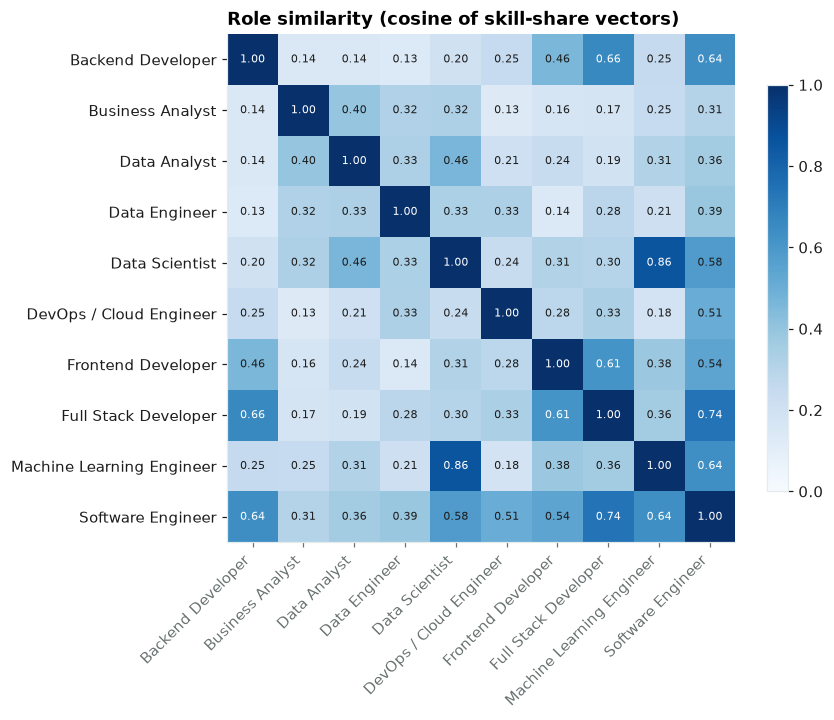

(                                                     most similar
 role                      role                                   
 Data Scientist            Machine Learning Engineer          0.86
 Full Stack Developer      Software Engineer                  0.74
 Backend Developer         Full Stack Developer               0.66
                           Software Engineer                  0.64
 Machine Learning Engineer Software Engineer                  0.64,
                                            least similar
 role              role                                  
 Data Engineer     Frontend Developer                0.14
 Backend Developer Data Engineer                     0.13
 Business Analyst  DevOps / Cloud Engineer           0.13)

In [12]:
vec = share.unstack(fill_value=0)
norm = vec.div(np.sqrt((vec ** 2).sum(axis=1)), axis=0)
sim = norm @ norm.T
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(sim.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(sim)), sim.index, rotation=45, ha="right")
ax.set_yticks(range(len(sim)), sim.index); ax.grid(False)
for (i, j), v in np.ndenumerate(sim.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
            color="white" if v > 0.6 else INK)
ax.set_title("Role similarity (cosine of skill-share vectors)")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIG / "08_role_similarity.png"); plt.show()
pairs_sim = (sim.where(np.triu(np.ones(sim.shape, bool), 1)).stack().dropna()
               .sort_values(ascending=False))
pairs_sim.head(5).round(2).to_frame("most similar"), pairs_sim.tail(3).round(2).to_frame("least similar")

## 9. Salaries

**What this shows:** how many postings advertise pay, and whether those numbers can be
trusted. Indian job ads rarely list pay, and the ones that do are messy: some amounts are
monthly or hourly (e.g. Rs 1,600 or Rs 30,000) and some ranges are meaningless
(e.g. Rs 0 to 55 lakh).

**Rule used (same as the app):** a salary counts only if it is not part-time, at least
Rs 1 lakh/year at the low end, at most Rs 1 crore/year, and the top of the range is no more
than 4x the bottom.

In [13]:
from skillpulse.analytics.market import PLAUSIBLE_SALARY_SQL

listed = q("SELECT count(*) AS n FROM jobs WHERE salary_min IS NOT NULL").n[0]
sal = q(f'''SELECT r.name AS role, salary_min::float AS lo, salary_max::float AS hi
            FROM jobs j JOIN roles r ON r.id = j.role_id WHERE {PLAUSIBLE_SALARY_SQL}''')
plausible_all = q(f"SELECT count(*) AS n FROM jobs WHERE {PLAUSIBLE_SALARY_SQL}").n[0]
print(f"Postings listing any salary: {listed} · plausible annual salaries: {plausible_all} "
      f"({listed - plausible_all} removed)")
sal["mid_lpa"] = (sal.lo + sal.hi.fillna(sal.lo)) / 2 / 1e5
(sal.groupby("role").mid_lpa.agg(["count", "median", "min", "max"]).round(1)
    .rename(columns={"count": "postings with pay", "median": "median LPA",
                     "min": "min LPA", "max": "max LPA"})
    .sort_values("postings with pay", ascending=False))

Postings listing any salary: 94 · plausible annual salaries: 76 (18 removed)


,postings with pay,median LPA,min LPA,max LPA
role,,,,
Full Stack Developer,8,19.2,6.0,25.0
DevOps / Cloud Engineer,6,16.2,6.0,25.0
Software Engineer,6,10.9,1.1,30.0
Backend Developer,5,17.5,6.0,22.0
Machine Learning Engineer,5,22.0,4.5,35.0
Data Analyst,5,6.0,5.0,25.0
Business Analyst,3,5.0,2.5,23.5
Data Engineer,2,25.2,20.5,30.0
Data Scientist,2,25.2,20.5,30.0


## 10. How accurate is the skill extraction?

**What this shows:** the extractor compared with hand labels (made by reading only the job
text; `annotator = claude`). The **test set** was labelled *before* any tuning and never
used to make fixes, so its numbers are the fair ones.

| Set | When | Precision | Recall | F1 |
|---|---|---|---|---|
| Test (90 jobs) | before tuning | 0.851 | 0.769 | 0.808 |
| Test (90 jobs) | after tuning | *computed below* | | |

In [14]:
import csv
from skillpulse.nlp.evalsets import labels_path, sample_path
from skillpulse.nlp.extractor import DictionaryExtractor

ex = DictionaryExtractor()
rows = []
for split in ["dev", "test"]:
    with open(sample_path(split), encoding="utf-8") as f:
        sample = {r["job_id"]: r for r in csv.DictReader(f)}
    with open(labels_path(split), encoding="utf-8") as f:
        labels = list(csv.DictReader(f))
    tp = fp = fn = 0
    for r in labels:
        truth = set(filter(None, r["skills"].split("|")))
        s = sample[r["job_id"]]
        pred = ex.extract(s["text"], s["title"])
        tp += len(truth & pred); fp += len(pred - truth); fn += len(truth - pred)
    p, rc = tp / (tp + fp), tp / (tp + fn)
    rows.append({"set": split, "jobs": len(labels), "precision": p, "recall": rc,
                 "F1": 2 * p * rc / (p + rc)})
pd.DataFrame(rows).set_index("set").round(3)

,jobs,precision,recall,F1
set,,,,
dev,144,0.894,0.894,0.894
test,90,0.936,0.860,0.896


## 11. Key findings

*Numbers below are from the run on 24 Nov 2026 (5 days of data, 20–24 Nov). Re-running
updates the tables above, but this text is fixed.*

1. **Dataset:** 1,463 postings from 619 companies. About half (48%) match one of our 10
   roles. Adzuna's search is loose, so a "data analyst" search also returns unrelated jobs.
   Those are kept out of role statistics.
2. **Location:** Bengaluru dominates (221 of 703 role-matched postings, 31%), then Hyderabad
   (116). Delhi NCR is thin (24).
3. **Text is truncated:** the median description is exactly **500 characters**. Adzuna
   sends previews, not full ads, so **29%** of role-matched postings show no skills at all.
   Among the rest, the median is 2 skills per posting.
4. **What's in demand (all roles):** Artificial Intelligence (21% of postings that list
   skills), Java (15%), Teamwork (14%), Machine Learning (12%), Python and Azure (11% each),
   AWS and Cloud Computing (10% each).
5. **Roles have clear signatures:** Backend means Java (56%); ML Engineer means AI (67%) and
   ML (61%); DevOps means Cloud (36%) and CI/CD (23%); Business Analyst means Requirements
   Gathering (29%); Data Analyst means Data Analysis (32%) and Power BI (15%).
6. **Skills come in stacks:** the strongest pairs are Infrastructure-as-Code + Kubernetes
   (lift 20), .NET + C# (19) and Spring Boot + Microservices (15). Employers hire for
   *stacks*, not single tools, which is useful advice for students.
7. **Role similarity:** Data Scientist and ML Engineer are almost the same skill profile
   (cosine 0.86); Full Stack and Software Engineer are close (0.74). Backend and
   Data Engineer (0.13) or Business Analyst and DevOps (0.13) have little in common.
8. **Salaries are scarce and messy:** only 6.4% of postings list pay, and 18 of those 94
   were implausible (monthly or hourly amounts, or ranges like Rs 0–55 lakh). After cleaning,
   no single role has 8+ salaries yet, so the app correctly says "not enough data".
9. **Extraction quality:** on the held-out test set, precision 0.936, recall 0.860,
   F1 0.896, which meets both project targets (0.85 / 0.80).

## 12. Limitations

- **Short history:** only 5 days, so no trend conclusions yet. The app's rising/falling
  view switches on after 28 days.
- **Truncated text:** 500-character previews hide many skills. Real demand is higher than
  the percentages shown, especially for skills listed near the end of an ad.
- **Coverage:** Adzuna aggregates many sites, but not every Indian job board, so this is a
  *sample* of the market, not all of it.
- **Role mapping is keyword-based:** titles that don't contain our keywords are left out.
- **Small groups:** some role × city groups have fewer than 10 postings (e.g. Frontend
  Developer: 9 in total), so their percentages are unreliable.
- **Labels:** the evaluation labels were made by Claude from job text only, not by a
  human. A human re-check of a sample would strengthen the result.
- **"AI" counts:** "Artificial Intelligence" includes jobs whose *title* contains "AI",
  which matches how jobs were labelled, but it counts a broad theme, not one tool.